---
title: "L3-06 · Derivatives and gradients"
short_title: "Derivatives and gradients"
subtitle: "Zoom in far enough on a smooth function and it looks linear; the derivative, and in several variables the gradient, is the slope of that linear picture, and the gradient points straight uphill across the level curves."
description: "Compute a derivative as a limit of difference quotients and a gradient from partial derivatives, and use the gradient to find the direction and rate of fastest local increase."
tags: [level-3, coursebook]
---

(lesson-l3-06)=

:::{div}
:class: qcai-meta
![Level 3 icon](../../_static/icons/qicon-level-3.svg) **Level 3 · High-school bridge** · about 90 minutes  
**Big idea.** Zoom in far enough on a smooth function and it looks linear; the derivative, and in several variables the gradient, is the slope of that linear picture, and the gradient points straight uphill across the level curves.  
**Before this lesson.** [L2-02](#lesson-l2-02), [L3-02](#lesson-l3-02)  
**Lab.** [Variational circuits and gradients](../../labs/08-variational-gradients.ipynb)
:::

## What you will be able to do

- Compute $f'(a)$ from the limit of difference quotients for a polynomial, and use the power, sum and product rules.
- Compute partial derivatives and the gradient $\nabla f$ of a function of two variables at a point.
- Prove that $D_u f = \nabla f \cdot u$ is largest along $\nabla f$, with value $|\nabla f|$, and that $\nabla f$ is perpendicular to level curves.
- Explain why the derivative of a fitted prediction is not by itself a causal effect.

## Why this matters

A hiker in fog can see only a few meters. Which way is uphill, and how steep is it? There is no global map, only local information, and yet the answer is precise: the slope in every direction is decided by just two numbers, the slopes east and north. That pair of numbers is the gradient, and the hiker's best direction is along it.

Machine learning trains models with millions of parameters the same way: compute the gradient of a loss and step against it ([L3-09](#lesson-l3-09)). Quantum circuit training does too. But local slope is easy to over-read. A fitted model's output may rise steeply with an input that has no effect at all when you change it by hand. This lesson builds the calculus carefully and ends with that caution.

:::{dropdown} Key terms

**Difference quotient**
: $\frac{f(a + h) - f(a)}{h}$, the slope of the secant line through $(a, f(a))$ and $(a + h, f(a + h))$.

**Derivative**
: $f'(a) = \lim_{h \to 0} \frac{f(a + h) - f(a)}{h}$ when the limit exists: the slope of the tangent line.

**Partial derivative**
: $\partial f/\partial x$: the derivative in $x$ with every other input held fixed.

**Gradient**
: $\nabla f = (\partial f/\partial x, \partial f/\partial y)$, the vector of partial derivatives.

**Directional derivative**
: $D_u f$: the rate of change of $f$ per unit distance in the direction of a unit vector $u$.

**Level curve**
: The set of points where $f(x, y)$ equals a fixed number $c$, like a contour line on a map.

:::


In [1]:
import sys, pathlib, subprocess
here = pathlib.Path.cwd()
root = next((p for p in [here, *here.parents] if (p / "qcai").is_dir()), None)
if root is None:  # for example on Google Colab: fetch the course's small teaching package
    root = pathlib.Path("quantum-causal-ai")
    if not root.exists():
        subprocess.run(["git", "clone", "--depth", "1", "https://github.com/pozapas/quantum-causal-ai.git", str(root)], check=True)
    root = root.resolve()
sys.path.insert(0, str(root))
from qcai.viz import show as _show, show_mpl as _show_mpl
from qcai.lessonfigs import l3_06 as _lessonfigs

## From secants to the tangent

A function ([L2-02](#lesson-l2-02)) turns an input into an output. The average rate of change of $f$ from $a$ to $a + h$ is the difference quotient, the slope of the secant line between the two points on the graph. For $f(x) = x^2$ at $a = 3$:

$$
\frac{f(3 + h) - f(3)}{h} = \frac{(3 + h)^2 - 9}{h} = \frac{6h + h^2}{h} = 6 + h \qquad (h \ne 0)
$$ (eq-l3-06-secant)

:::{prf:definition} Derivative
:label: def-l3-06-derivative
A function $f$ is **differentiable** at $a$ if the limit $f'(a) = \lim_{h \to 0} \frac{f(a + h) - f(a)}{h}$ exists (as a finite number, with $h$ approaching 0 from both sides). The number $f'(a)$ is the **derivative** of $f$ at $a$, and the line $y = f(a) + f'(a)(x - a)$ is the **tangent line** [@openstax_derivative].
:::

:::{figure} ../../_static/animations/l3_06_secant_tangent.mp4
:alt: The parabola y = x squared with a point at (3, 9). An orange secant line through a second point slides toward (3, 9) as h shrinks, its slope readout falling from 8 to 6.01, and the red tangent line of slope 6 appears.
:width: 100%

Equation [](#eq-l3-06-secant) in motion: as the second point slides toward $(3, 9)$, the secant slope $6 + h$ falls toward 6, the slope of the tangent.
:::

:::{dropdown} What the animation shows
The graph of $f(x) = x^2$ for $x$ from 0 to 5 shows the point $(3, 9)$ and a second point at $x = 3 + h$, joined by an orange secant line, with dashed run $h$ and rise $f(3 + h) - 9$. A panel simplifies the slope: $\frac{f(3 + h) - f(3)}{h}$ becomes $\frac{(3 + h)^2 - 9}{h}$, then $\frac{6h + h^2}{h}$, then $6 + h$. Live readouts show $h$ and $6 + h$ as $h$ shrinks from 2 to 1 to 0.25 to 0.01; the slope goes from 8.000 to 6.010 and the secant line closes in on the curve. Finally the red tangent line $y = 9 + 6(x - 3)$ is drawn and the panel states $f'(3) = \lim_{h \to 0} (6 + h) = 6$.
:::

So $f'(3) = \lim_{h \to 0}(6 + h) = 6$. Near $x = 3$ a small step $\Delta x$ changes $x^2$ by about $6\,\Delta x$: from 3 to 3.01 the exact change is $9.0601 - 9 = 0.0601$, against the estimate $0.06$.

:::{prf:proposition} Differentiable means locally linear
:label: prop-l3-06-linear
$f$ is differentiable at $a$ with derivative $m$ if and only if $f(a + h) = f(a) + m h + r(h)$ with an error $r(h)$ satisfying $r(h)/h \to 0$ as $h \to 0$.
:::

:::{prf:proof}
Define $r(h) = f(a + h) - f(a) - mh$. Then $r(h)/h = \frac{f(a + h) - f(a)}{h} - m$, which tends to 0 exactly when the difference quotient tends to $m$. For $x^2$ at 3 the error is $r(h) = h^2$, and $h^2/h = h \to 0$.
:::

## Rules that save work

:::{prf:theorem} Power rule
:label: thm-l3-06-power
For every whole number $n \ge 1$, the derivative of $x^n$ is $n x^{n-1}$.
:::

:::{prf:proof}
By the binomial theorem, $(x + h)^n = x^n + n x^{n-1} h + \binom{n}{2} x^{n-2} h^2 + \dots + h^n$. Subtract $x^n$ and divide by $h \ne 0$: $\frac{(x + h)^n - x^n}{h} = n x^{n-1} + h\left(\binom{n}{2} x^{n-2} + \dots + h^{n-2}\right)$. The bracket stays bounded as $h \to 0$, so the second term tends to 0 and the limit is $n x^{n-1}$.
:::

Three more rules follow from the definition in the same way [@mml]: the **sum rule** $(f + g)' = f' + g'$ (and $(cf)' = cf'$), the **product rule** $(fg)' = f'g + fg'$, and the **chain rule** $\frac{d}{dx} f(g(x)) = f'(g(x))\, g'(x)$. For example, $\frac{d}{dx}(3x^4 - 5x) = 12x^3 - 5$, and $\frac{d}{dx}(x^2 + 1)^5 = 5(x^2 + 1)^4 \cdot 2x$.


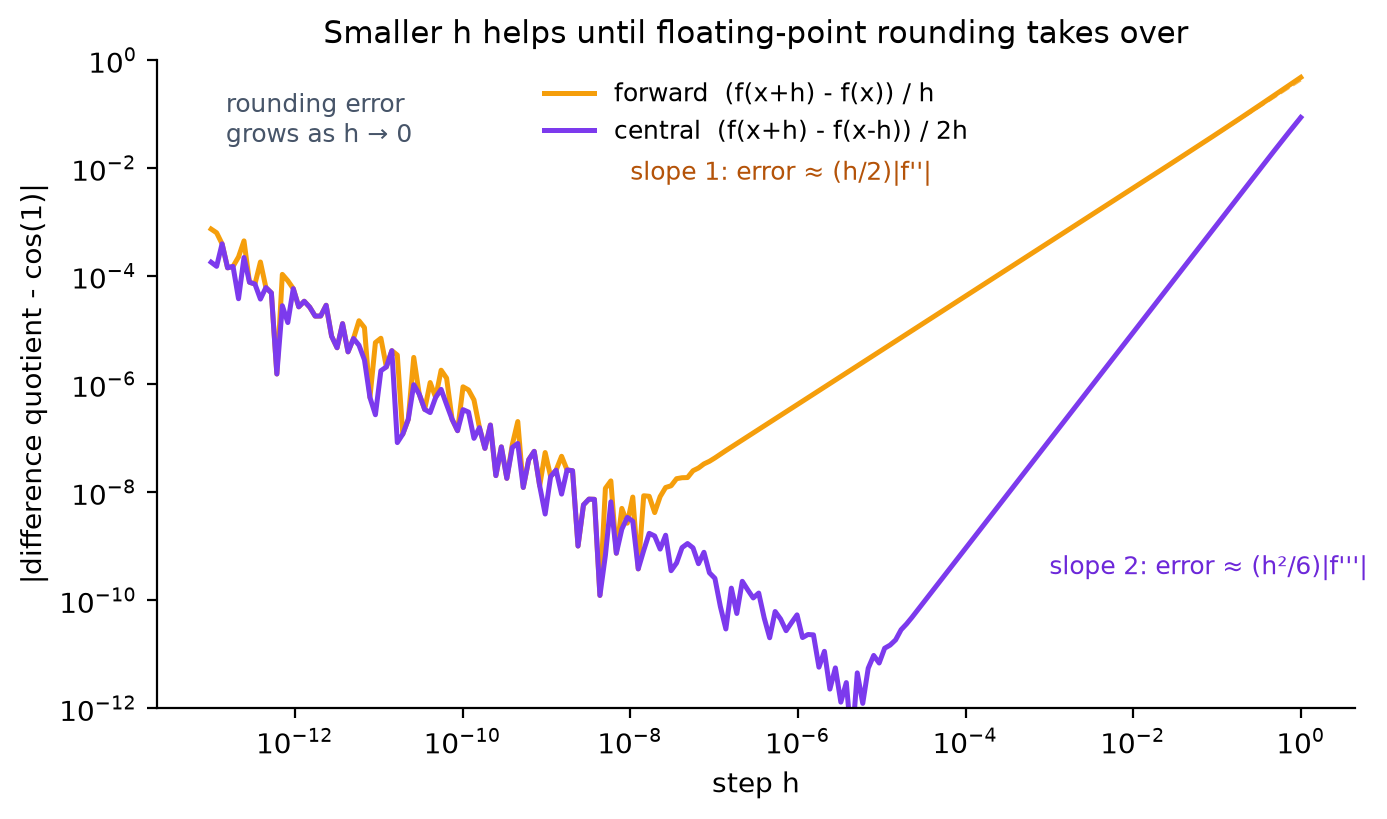

In [2]:
_show_mpl(_lessonfigs.difference_errors())

*In a computer, $h$ cannot be taken to 0. The forward quotient has error about $\frac h2|f''|$ (slope 1 on this log-log plot), the central quotient about $\frac{h^2}{6}|f'''|$ (slope 2). Below about $h = 10^{-8}$ and $10^{-5}$ respectively, floating-point rounding dominates and the error grows again.*

:::{warning} Not every function has a derivative everywhere
For $f(x) = |x|$ at 0, the difference quotient is $|h|/h$, which is $+1$ for $h > 0$ and $-1$ for $h < 0$. The two one-sided limits disagree, so $f'(0)$ does not exist: the graph has a corner. Functions in this lesson are assumed smooth (all derivatives we use exist and are continuous).
:::

## Several inputs: partial derivatives and the gradient

:::{prf:definition} Partial derivatives and gradient
:label: def-l3-06-gradient
For $f(x, y)$, the **partial derivative** $\frac{\partial f}{\partial x}(a, b)$ is the ordinary derivative of $x \mapsto f(x, b)$ at $x = a$, with $y$ held at $b$; similarly for $\frac{\partial f}{\partial y}$. The **gradient** is the vector $\nabla f(a, b) = \left(\frac{\partial f}{\partial x}(a, b), \frac{\partial f}{\partial y}(a, b)\right)$.
:::

$$
g(x, y) = x^2 + 3y^2, \qquad \nabla g = (2x,\ 6y), \qquad \nabla g(2, -1) = (4, -6)
$$ (eq-l3-06-grad)

:::{prf:definition} Directional derivative
:label: def-l3-06-directional
For a unit vector $u = (u_1, u_2)$, the **directional derivative** is $D_u f(a, b) = \lim_{h \to 0} \frac{f(a + h u_1, b + h u_2) - f(a, b)}{h}$, the slope of $f$ when you walk from $(a, b)$ in direction $u$.
:::

:::{prf:theorem} Directional derivatives come from the gradient
:label: thm-l3-06-dot
If $f$ has continuous partial derivatives near $(a, b)$, then $D_u f(a, b) = \nabla f(a, b) \cdot u = \frac{\partial f}{\partial x}u_1 + \frac{\partial f}{\partial y}u_2$.
:::

:::{prf:proof}
(Sketch.) Walk in two legs: first change $y$ by $hu_2$, then $x$ by $hu_1$. By the one-variable mean value theorem, $f(a + hu_1, b + hu_2) - f(a, b) = \frac{\partial f}{\partial x}(\xi, b + hu_2)\, hu_1 + \frac{\partial f}{\partial y}(a, \eta)\, hu_2$ for some $\xi$ between $a$ and $a + hu_1$ and $\eta$ between $b$ and $b + hu_2$. Divide by $h$ and let $h \to 0$; continuity of the partial derivatives sends both to their values at $(a, b)$. A full proof is in [@openstax_gradient].
:::

:::{prf:theorem} The gradient is the direction of steepest ascent
:label: thm-l3-06-steepest
Let $\nabla f(a, b) \ne 0$ and $f$ be as above. Among unit vectors $u$, $D_u f(a, b)$ is largest when $u = \nabla f/|\nabla f|$, where it equals $|\nabla f|$; it is smallest, $-|\nabla f|$, for $u = -\nabla f/|\nabla f|$; and it is 0 exactly when $u \perp \nabla f$.
:::

:::{prf:proof}
By the previous theorem and the geometry of the dot product ([L3-02](#lesson-l3-02)), $D_u f = \nabla f \cdot u = |\nabla f|\,|u|\cos\theta = |\nabla f|\cos\theta$, where $\theta$ is the angle between $u$ and $\nabla f$. Since $-1 \le \cos\theta \le 1$ (the Cauchy-Schwarz inequality), $-|\nabla f| \le D_u f \le |\nabla f|$, with the top value at $\theta = 0$, the bottom at $\theta = \pi$, and 0 at $\theta = \pm\pi/2$.
:::

:::{figure} ../../_static/animations/l3_06_contour_gradient.mp4
:alt: Elliptical level curves of g = x squared plus 3 y squared. At the point (2, -1) a red gradient arrow crosses the level curve g = 7 at a right angle; an orange direction arrow turns around the point with a live readout of the directional derivative.
:width: 100%

Level curves of $g(x, y) = x^2 + 3y^2$ on equal axes. The gradient $(4, -6)$ at $(2, -1)$ is perpendicular to the level curve; turning the direction $u$ shows $D_u g$ peaking at $\sqrt{52} \approx 7.21$ along the gradient.
:::

:::{dropdown} What the animation shows
Ellipses show the level curves $g = 1, 4, 7, 10, 13$ of $g(x, y) = x^2 + 3y^2$, with the curve $g = 7$ highlighted; $x$ and $y$ use the same scale. At the point $(2, -1)$, which lies on $g = 7$, the formula $\nabla g = (2x, 6y) = (4, -6)$ appears and a red arrow points along it, down and to the right. A violet tangent segment to the level curve and a right-angle mark show that the gradient is perpendicular to the curve. Then an orange unit vector $u$ turns around the point while a readout shows $D_u g = \nabla g \cdot u = |\nabla g|\cos\theta$. Along the level curve the readout is 0; aligned with the gradient it reaches $\max_u D_u g = |\nabla g| = \sqrt{52} \approx 7.21$; pointing opposite the gradient it is $-7.21$, the direction of steepest descent.
:::

:::{prf:corollary} The gradient is perpendicular to level curves
:label: cor-l3-06-perp
If $r(s) = (x(s), y(s))$ is a smooth curve along which $f(r(s)) = c$ is constant, then $\nabla f(r(s)) \cdot r'(s) = 0$: the gradient is perpendicular to the tangent of the level curve.
:::

:::{prf:proof}
Differentiate $f(x(s), y(s)) = c$ with the multivariable chain rule (which follows from the same two-leg argument): $\frac{\partial f}{\partial x}x'(s) + \frac{\partial f}{\partial y}y'(s) = 0$, that is $\nabla f \cdot r'(s) = 0$. For $g$ at $(2, -1)$: the tangent direction $(3, 2)$ gives $(4, -6)\cdot(3, 2) = 12 - 12 = 0$.
:::


In [3]:
_show(_lessonfigs.gradient_compass())

**Explore.** Pick the direction $u$ with the slider. The right panel plots $D_u g = 4\cos\alpha - 6\sin\alpha$ against the angle $\alpha$ of $u$; the red diamond marks the maximum $\sqrt{52} \approx 7.21$ at about $303.7^\circ$, the direction of $(4, -6)$.

:::{dropdown} What the figure shows
The first panel shows level curves of $g(x, y) = x^2 + 3y^2$ on equal axes, the point $(2, -1)$, a red arrow in the gradient direction and an orange arrow for the chosen unit direction $u$ at angle $\alpha$ (0 to 330 degrees in steps of 30). The second panel plots the directional derivative $D_u g = 4\cos\alpha - 6\sin\alpha$, a sine wave between $-7.21$ and $7.21$, with a marker at the chosen angle: 4 at $0^\circ$, $-6$ at $90^\circ$, and the maximum $\sqrt{52} \approx 7.21$ at about $303.7^\circ$ marked by a diamond.
:::

## The picture in three dimensions

The graph of $g$ is a bowl-shaped surface $z = x^2 + 3y^2$ over the $xy$-plane, and the level curves are its contour lines, drawn on the floor. Slicing the surface through the point $(2, -1, 7)$ in direction $u$ gives a curve whose slope at that point is $D_u g$.

:::{figure} ../../_static/animations/l3_06_steepest_surface.mp4
:alt: A translucent bowl surface over elliptical contour lines. A point on the bowl above (2, -1) has a short orange tangent segment that turns; it is steepest when it lies above the red gradient arrow on the floor.
:width: 100%

The surface $z = x^2 + 3y^2$ with its contour map. The orange tangent segment through $(2, -1, 7)$ turns with $u$; it climbs fastest, with slope $\sqrt{52} \approx 7.21$, directly above the gradient arrow drawn in the input plane.
:::

:::{dropdown} What the animation shows
Three-dimensional axes show the surface $z = x^2 + 3y^2$ over $-2.4 \le x \le 2.4$, $-1.45 \le y \le 1.45$ (the vertical axis is drawn at one quarter scale), above the level curves $g = 1, 4, 7, 10$ on the floor. A dot marks $(2, -1, 7)$ on the surface with a dashed drop line to $(2, -1)$ on the floor, where a red arrow shows the gradient $(4, -6)$, an arrow in the input plane, not on the surface. An orange segment tangent to the surface turns with a unit direction $u$, also drawn on the floor, and a readout gives its slope $D_u g$: negative when $u$ points against the gradient, zero along the level curve, and largest, $\sqrt{52} \approx 7.21$, when $u$ lies along the gradient. The camera then swings around to show the steepest segment directly above the red arrow.
:::

:::{prf:remark} Where the gradient lives
The gradient of $g(x, y)$ has two components, so it is an arrow in the input plane, not on the surface. It tells you which way to move the inputs; the surface tells you what happens to the output. Gradient descent ([L3-09](#lesson-l3-09)) moves the inputs a small step in the direction $-\nabla g$.
:::

## Compute it, and a caution about causes

Difference quotients, the gradient by formula and by central differences, a brute-force search confirming that the largest directional derivative is $\sqrt{52}$ along $\nabla g$, and the linear approximation from the worked example.


In [4]:
import math
import numpy as np

# 1. secant slopes of f(x) = x^2 at x = 3 approach 6, and equal 6 + h exactly
f = lambda x: x ** 2
for h in (1, 0.1, 0.01, 0.001):
    print(f'h = {h:<6} secant slope = {(f(3 + h) - f(3)) / h:.6f}   6 + h = {6 + h}')

# 2. forward versus central differences for sin at x = 1 (exact derivative cos 1)
for h in (1e-2, 1e-4, 1e-6):
    fwd = (math.sin(1 + h) - math.sin(1)) / h
    cen = (math.sin(1 + h) - math.sin(1 - h)) / (2 * h)
    print(f'h = {h:.0e}  forward error {abs(fwd - math.cos(1)):.2e}  central error {abs(cen - math.cos(1)):.2e}')

# 3. the gradient of g(x, y) = x^2 + 3y^2 at (2, -1), by formula and by central differences
g = lambda x, y: x ** 2 + 3 * y ** 2
def num_grad(F, x, y, h=1e-6):
    return np.array([(F(x + h, y) - F(x - h, y)) / (2 * h), (F(x, y + h) - F(x, y - h)) / (2 * h)])
grad = np.array([2 * 2, 6 * (-1)])
print('formula gradient', grad, '  numerical', num_grad(g, 2, -1).round(6))

# 4. directional derivatives over 3600 directions: the largest is |grad g| = sqrt(52), along grad g
ang = np.linspace(0, 2 * np.pi, 3600, endpoint=False)
D = grad[0] * np.cos(ang) + grad[1] * np.sin(ang)
k = int(D.argmax())
print('max D_u g =', round(float(D[k]), 4), ' sqrt(52) =', round(math.sqrt(52), 4))
print('at angle', round(math.degrees(ang[k]), 1), ' angle of grad g =', round(math.degrees(math.atan2(-6, 4)) % 360, 1))
tangent = np.array([3, 2]) / math.sqrt(13)
print('grad g . (3, 2)/sqrt(13) =', float(grad @ tangent))

# 5. linear approximation for the worked example F(x, y) = x^2 y + y^3 near (1, 2)
F = lambda x, y: x ** 2 * y + y ** 3
lin = F(1, 2) + 4 * 0.1 + 13 * (-0.1)
print('F(1.1, 1.9) exact', round(F(1.1, 1.9), 4), ' linear estimate', round(lin, 4))

h = 1      secant slope = 7.000000   6 + h = 7
h = 0.1    secant slope = 6.100000   6 + h = 6.1
h = 0.01   secant slope = 6.010000   6 + h = 6.01
h = 0.001  secant slope = 6.001000   6 + h = 6.001
h = 1e-02  forward error 4.22e-03  central error 9.00e-06
h = 1e-04  forward error 4.21e-05  central error 9.00e-10
h = 1e-06  forward error 4.21e-07  central error 2.77e-11
formula gradient [ 4 -6]   numerical [ 4. -6.]
max D_u g = 7.2111  sqrt(52) = 7.2111
at angle 303.7  angle of grad g = 303.7
grad g . (3, 2)/sqrt(13) = 0.0
F(1.1, 1.9) exact 9.158  linear estimate 9.1


```{mermaid}
graph LR
  Z["Z: common cause"] --> X["X: input to the model"]
  Z --> Y["Y: outcome"]
```

*The data in the next cell come from this graph: $Z$ causes both $X$ and $Y$, and there is no arrow from $X$ into $Y$: $X$ has no effect on $Y$. A model that predicts $Y$ from $X$ still has a positive derivative in $X$.*

A fitted prediction function has a derivative, but that derivative describes how predictions change across observed data, not what happens if you set $X$ by hand. Here the fitted slope is about 1.6 while the effect of setting $X$ is 0.


In [5]:
# a fitted slope is not an intervention: Z drives both X and Y, and X has no effect on Y
rng = np.random.default_rng(0)
n = 20000
Z = rng.normal(size=n)
X = Z + 0.5 * rng.normal(size=n)          # Var X = 1.25
Y = 2 * Z + 0.5 * rng.normal(size=n)      # Y does not depend on X at all
slope = np.polyfit(X, Y, 1)[0]
print('derivative of the fitted line dY/dX:', round(float(slope), 3), ' (population value 2 / 1.25 = 1.6)')

# intervene: set X by hand (do(X = x)); Y's mechanism ignores X, so nothing changes
X_set = rng.normal(size=n) * 3
Y_after = 2 * Z + 0.5 * rng.normal(size=n)
print('slope after setting X by hand:', round(float(np.polyfit(X_set, Y_after, 1)[0]), 3))

derivative of the fitted line dY/dX: 1.591  (population value 2 / 1.25 = 1.6)
slope after setting X by hand: 0.003


:::{caution} A partial derivative is not a causal effect
Holding the other inputs of a formula fixed is a mathematical operation. Intervening on a variable in the world can change other variables through causal mechanisms, or nothing at all. To read a derivative causally you must name the causal model and the intervention it represents ([L2-08](#lesson-l2-08), Level 4) [@peters].
:::

## Worked example

:::{admonition} Gradient, a directional derivative, and a linear estimate
:class: tip

Let $F(x, y) = x^2 y + y^3$. At the point $(1, 2)$ find $\nabla F$, the directional derivative toward the unit vector $u = (3, 4)/5$, the largest possible rate of increase, and a linear estimate of $F(1.1, 1.9)$.

1. Partial derivatives: $\partial F/\partial x = 2xy$ and $\partial F/\partial y = x^2 + 3y^2$. At $(1, 2)$: $2 \cdot 1 \cdot 2 = 4$ and $1 + 12 = 13$, so $\nabla F(1, 2) = (4, 13)$.
2. Directional derivative: $D_u F = (4, 13)\cdot(3, 4)/5 = (12 + 52)/5 = 64/5 = 12.8$.
3. Largest rate: $|\nabla F| = \sqrt{16 + 169} = \sqrt{185} \approx 13.60$, in the direction $(4, 13)/\sqrt{185}$. Check: $12.8 < 13.60$, as the steepest-ascent theorem requires.
4. Linear estimate: $F(1, 2) = 2 + 8 = 10$, and the step is $(0.1, -0.1)$, so $F(1.1, 1.9) \approx 10 + 4(0.1) + 13(-0.1) = 9.1$.
5. Exact value: $1.21 \cdot 1.9 + 1.9^3 = 2.299 + 6.859 = 9.158$. The error 0.058 is of the size of the squared step, as local linearity predicts.

**Result.** $\nabla F(1, 2) = (4, 13)$; $D_u F = 12.8$ toward $(3, 4)/5$; the steepest rate is $\sqrt{185} \approx 13.60$; the linear estimate 9.1 is close to the exact 9.158.
:::

## Exercises

**1. (Core)** Use the definition (the limit of difference quotients) to find the derivative of $x^3$ at $x = 2$.

:::{dropdown} Solution
$(2 + h)^3 = 8 + 12h + 6h^2 + h^3$, so $\frac{(2 + h)^3 - 8}{h} = 12 + 6h + h^2$ for $h \ne 0$. As $h \to 0$ this tends to 12, so the derivative is 12, matching the power rule $3x^2 = 12$ at $x = 2$.
:::

**2. (Core)** For $g(x, y) = x^2 + 3y^2$, find $\nabla g(2, -1)$ and the directional derivatives at $(2, -1)$ toward $(1, 0)$, toward $(0, 1)$, and toward $(1, 1)/\sqrt2$.

:::{dropdown} Solution
$\nabla g = (2x, 6y) = (4, -6)$. Toward $(1, 0)$: $4$. Toward $(0, 1)$: $-6$ (moving north lowers $g$, since $y = -1$ moves toward 0). Toward $(1, 1)/\sqrt2$: $(4 - 6)/\sqrt2 = -\sqrt2 \approx -1.414$.
:::

**3. (Stretch)** At $(2, -1)$, give a unit vector for the direction of steepest descent of $g = x^2 + 3y^2$ and a unit vector along which $g$ does not change to first order. Check the second against the level curve $g = 7$.

:::{dropdown} Solution
Steepest descent is $-\nabla g/|\nabla g| = (-4, 6)/\sqrt{52} = (-2, 3)/\sqrt{13}$. A perpendicular unit vector is $(3, 2)/\sqrt{13}$, since $(4, -6)\cdot(3, 2) = 0$. The level curve $x^2 + 3y^2 = 7$ can be written $x = \sqrt7\cos s$, $y = \sqrt{7/3}\sin s$; at $(2, -1)$ its tangent $(-\sqrt7\sin s, \sqrt{7/3}\cos s)$ has $\sin s = -\sqrt{3/7}$ and $\cos s = 2/\sqrt7$, giving $(\sqrt3, 2/\sqrt3)$, a multiple of $(3, 2)$.
:::

**4. (Stretch)** Prove the product rule $(fg)'(a) = f'(a)g(a) + f(a)g'(a)$ for functions differentiable at $a$.

:::{dropdown} Solution
Add and subtract $f(a + h)g(a)$: $\frac{f(a + h)g(a + h) - f(a)g(a)}{h} = f(a + h)\frac{g(a + h) - g(a)}{h} + g(a)\frac{f(a + h) - f(a)}{h}$. As $h \to 0$, the difference quotients tend to $g'(a)$ and $f'(a)$, and $f(a + h) \to f(a)$ because a differentiable function is continuous ($f(a + h) - f(a) = h \cdot \frac{f(a + h) - f(a)}{h} \to 0 \cdot f'(a) = 0$). The limit is $f(a)g'(a) + g(a)f'(a)$.
:::

**5. (Challenge)** Show that for $f(x) = x^2$ the forward quotient $\frac{f(x + h) - f(x)}{h}$ has error exactly $h$ and the central quotient $\frac{f(x + h) - f(x - h)}{2h}$ has error exactly 0. Then use $f(x \pm h) = f(x) \pm hf'(x) + \frac{h^2}{2}f''(x) \pm \frac{h^3}{6}f'''(x) + \dots$ to explain the slopes 1 and 2 in the figure for a general smooth $f$.

:::{dropdown} Solution
Forward: $\frac{(x + h)^2 - x^2}{h} = 2x + h$, error $h$. Central: $\frac{(x + h)^2 - (x - h)^2}{2h} = \frac{4xh}{2h} = 2x$, error 0. In general the forward quotient is $f'(x) + \frac h2 f''(x) + O(h^2)$, error proportional to $h$ (slope 1 on a log-log plot). In the central quotient the even terms cancel: $\frac{f(x + h) - f(x - h)}{2h} = f'(x) + \frac{h^2}{6}f'''(x) + O(h^4)$, error proportional to $h^2$ (slope 2). For $x^2$, $f''' = 0$, so the central error vanishes, and the forward error $\frac h2 f'' = h$ matches.
:::

**6. (Challenge)** In the second code cell, $Z$ and the two noise terms are independent with variances 1, 0.25 and 0.25, $X = Z + \text{noise}$ and $Y = 2Z + \text{noise}$. The least-squares slope of $Y$ on $X$ is $\operatorname{Cov}(X, Y)/\operatorname{Var}(X)$. Compute it, and explain why the derivative of the fitted line is not the effect of setting $X$.

:::{dropdown} Solution
$\operatorname{Cov}(X, Y) = \operatorname{Cov}(Z, 2Z) = 2\operatorname{Var}(Z) = 2$ (the noises are independent of everything) and $\operatorname{Var}(X) = 1 + 0.25 = 1.25$, so the slope is $2/1.25 = 1.6$. The fitted line predicts $Y$ well from $X$ because both carry information about $Z$. But $Y$'s mechanism does not use $X$, so setting $X$ by hand leaves the distribution of $Y$ unchanged: the causal effect is 0. The derivative 1.6 describes association in the observed data, not intervention.
:::

## Check your understanding

**1. What is the slope of the secant line of $f(x) = x^2$ through $x = 3$ and $x = 3 + h$?**

- **A.** $2h$
- **B.** $6 + h$
- **C.** $6$
- **D.** $9 + h^2$

:::{dropdown} Show the answer
**B. $6 + h$**

$\frac{(3 + h)^2 - 9}{h} = \frac{6h + h^2}{h} = 6 + h$ for $h \ne 0$. Its limit as $h \to 0$ is the derivative 6, but each secant slope is $6 + h$.
:::

**2. For $g(x, y) = x^2 + 3y^2$ at $(2, -1)$, in which direction does $g$ increase fastest, and how fast?**

- **A.** Along $(2, -1)$, at rate $\sqrt5$
- **B.** Along $(1, 0)$, at rate 4
- **C.** Along $(3, 2)$, at rate 0
- **D.** Along $(4, -6)$, at rate $\sqrt{52}$

:::{dropdown} Show the answer
**D. Along $(4, -6)$, at rate $\sqrt{52}$**

$\nabla g(2, -1) = (4, -6)$. The directional derivative $\nabla g \cdot u$ is largest for $u$ along $\nabla g$, with value $|\nabla g| = \sqrt{16 + 36} = \sqrt{52} \approx 7.21$. Along $(3, 2)$ the rate is 0: that is the level-curve direction.
:::

**3. A model predicts $Y$ from $X$, and its derivative in $X$ is large and positive. What does that establish about the causal effect of $X$ on $Y$?**

- **A.** That there is no confounding
- **B.** Nothing by itself; a causal model and assumptions are needed
- **C.** That the effect is large and positive
- **D.** That the effect is positive but smaller

:::{dropdown} Show the answer
**B. Nothing by itself; a causal model and assumptions are needed**

A prediction function reflects associations, which can come from a common cause or selection. In the code example the fitted slope is 1.6 while setting $X$ has no effect. A causal reading needs a justified model of the intervention.
:::

**4. For the function $f(x) = x^2$, what is $f(3 + h) - f(3)$?** *(Review of [L2-02](#lesson-l2-02))*

- **A.** $6h$
- **B.** $h^2$
- **C.** $6h + h^2$
- **D.** $9 + h^2$

:::{dropdown} Show the answer
**C. $6h + h^2$**

Evaluate the rule at the input $3 + h$: $(3 + h)^2 = 9 + 6h + h^2$, then subtract $f(3) = 9$ to get $6h + h^2$. Evaluating a function at a shifted input is the first step of every difference quotient.
:::

## Common misconceptions

- **"The derivative is the slope between two nearby points."** That is a secant slope, $6 + h$ for $x^2$ at 3. The derivative is the limit as $h \to 0$, here exactly 6. In computation, a finite $h$ gives an approximation whose error depends on $h$ and on rounding.
- **"The gradient is an arrow on the surface pointing uphill."** The gradient of $f(x, y)$ is a vector in the input plane. It tells you which way to move $(x, y)$; the steepest path on the surface lies above it.
- **"The gradient points toward the maximum of the function."** It points in the direction of fastest local increase, perpendicular to the level curve through the point. For elongated level curves, as for $x^2 + 3y^2$, it does not point straight at (or away from) the minimum: at $(2, -1)$ it is along $(4, -6)$, not along $(2, -1)$.

:::{caution} Scope and limits
Functions here are assumed smooth: partial derivatives exist and are continuous where used, which justifies $D_u f = \nabla f \cdot u$. Without continuity of the partials a function can have both partial derivatives at a point and still fail to be differentiable there. The chain rule and the mean value theorem are used with only a sketch of proof. Finite-difference computations carry truncation and rounding error. Derivatives describe mathematical change; connecting them to interventions requires separate causal assumptions.
:::

:::{seealso} Where this leads
Gradient descent and learning rates are the subject of [L3-09](#lesson-l3-09), where the curvatures of a quadratic loss decide convergence (for a general quadratic these are eigenvalues of a symmetric matrix, [L3-05](#lesson-l3-05)). In Level 4 the question of when a derivative is a causal effect becomes precise, and in [L7-02](#lesson-l7-02) gradients of quantum circuit outputs with respect to gate angles are obtained by the parameter-shift rule, which expresses each partial derivative through circuit runs at shifted angles [@schuld].
:::

:::{dropdown} For instructors

**Why this lesson.** Derivatives and gradients are the working tools of optimization in machine learning and of variational quantum algorithms. Grounding them in the limit of secant slopes and in the geometry of level curves prevents the common view of a gradient as a formula to differentiate and nothing more [@openstax_derivative; @openstax_gradient; @mml].

**Teaching notes.**

- Have students compute $6 + h$ for $h = 1, 0.1, 0.01$ by hand before showing the animation, so that the limit is something they predict.
- Draw level curves on graph paper with equal scales and ask students to sketch the steepest uphill direction at a point; then compute $\nabla g$ and compare. With unequal scales the right angle disappears, a good discussion point.
- Use the interactive figure to connect the sine-shaped curve $4\cos\alpha - 6\sin\alpha$ with $|\nabla g|\cos\theta$: the amplitude of the wave is $|\nabla g|$.
- End with the confounded regression in the second code cell and ask what experiment would measure the effect of $X$.

**Assessment.** The core exercises check computation from the definition and from formulas; the stretch exercises check geometric reasoning and proof; the challenge exercises connect numerical error to Taylor expansion and separate predictive derivatives from causal effects.

**Going further.** Define the Hessian matrix of second partial derivatives, compute it for $g(x, y) = x^2 + 3y^2$ (it is $\operatorname{diag}(2, 6)$), and relate its eigenvalues ([L3-05](#lesson-l3-05)) to the shape of the level curves. Mathematics for Machine Learning, chapter 5, covers vector calculus for learning [@mml].

:::

## References

This lesson draws on [@openstax_derivative; @openstax_gradient; @mml; @peters; @schuld].

**Further reading.**

- [@openstax_gradient]: Section 4.6 proves the directional derivative formula and the steepest-ascent property with worked examples.
- [@mml]: Chapter 5 develops gradients of vector-valued functions and backpropagation.

**Next:** [L3-07 · Expectation and variance](#lesson-l3-07)
